In [1]:
print("Ranjeet-100 epochs")

Ranjeet-100 epochs


In [1]:
import os
import rasterio
import numpy as np
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader

class BEN14KDataset(Dataset):
    def __init__(self, data_dir, parquet_file, split='train'):
        """
        data_dir: Path to the extracted BEN_14k directory
        parquet_file: Path to metadata.parquet
        split: 'train', 'validation', or 'test'
        """
        self.data_dir = data_dir
        self.split = split
        
        print(f"Loading {split} metadata...")
        df = pd.read_parquet(parquet_file)
        df = df[df['split'] == split]
        
        s1_folder = os.path.join(data_dir, 'BigEarthNet-S1', split)
        s2_folder = os.path.join(data_dir, 'BigEarthNet-S2', split)
        
        # --- BULLETPROOF FIX: Physically check the disk ---
        self.valid_pairs = []
        self.patch_ids = []    # Naya: Save patch IDs
        self.labels = []       # Naya: Save ISRO labels for evaluation
        
        for _, row in df.iterrows():
            # Get possible names from metadata
            patch_id = row.get('patch_id', '')
            s1_name = row.get('s1_name', '')
            s2_name = row.get('s2v1_name', '')
            img_labels = row.get('labels', []) # Parquet file se labels uthao
            
            # 1. Check S2 File
            s2_path = None
            if os.path.exists(os.path.join(s2_folder, f"{patch_id}.tif")):
                s2_path = os.path.join(s2_folder, f"{patch_id}.tif")
            elif os.path.exists(os.path.join(s2_folder, f"{s2_name}.tif")):
                s2_path = os.path.join(s2_folder, f"{s2_name}.tif")
                
            # 2. Check S1 File
            s1_path = None
            if os.path.exists(os.path.join(s1_folder, f"{patch_id}.tif")):
                s1_path = os.path.join(s1_folder, f"{patch_id}.tif")
            elif os.path.exists(os.path.join(s1_folder, f"{s1_name}.tif")):
                s1_path = os.path.join(s1_folder, f"{s1_name}.tif")
                
            # 3. If BOTH files physically exist on your drive, keep them!
            if s1_path and s2_path:
                self.valid_pairs.append((s1_path, s2_path))
                self.patch_ids.append(patch_id)
                self.labels.append(img_labels)
                
        # Ab yeh exactly 7180 print karega (kyunki utni hi files aapke folder me hain!)
        print(f"Found {len(self.valid_pairs)} ACTUALLY EXISTING image pairs on disk for {split}.")

    def __len__(self):
        return len(self.valid_pairs)

    def read_tif(self, path):
        with rasterio.open(path) as src:
            return src.read()

    def __getitem__(self, idx):
        # We stored the EXACT valid file paths directly, so no strings can mismatch here
        s1_path, s2_path = self.valid_pairs[idx]
        
        # Read the images
        s1_img = self.read_tif(s1_path) # Sentinel-1 (VV, VH)
        s2_img = self.read_tif(s2_path) # Sentinel-2 (Multispectral)
        
        # --- NORMALIZATION ---
        # SAR: Clip outliers and normalize to [0, 1]
        s1_img = np.clip(s1_img, -25.0, 0.0)
        s1_img = (s1_img - (-25.0)) / 25.0
        
        # Optical: Sentinel-2 reflectance ranges 0 to 10000 -> Normalize to [0, 1]
        s2_img = np.clip(s2_img, 0, 10000) / 10000.0
        
        # Convert to PyTorch tensors
        s1_tensor = torch.tensor(s1_img, dtype=torch.float32)
        s2_tensor = torch.tensor(s2_img, dtype=torch.float32)
        
        return s1_tensor, s2_tensor

# --- Test the DataLoader ---
if __name__ == "__main__":
    DATA_DIR = r"C:\Users\ranje\Downloads\ISRO\archive\BEN_14k"
    PARQUET_FILE = r"C:\Users\ranje\Downloads\ISRO\archive\BEN_14k\metadata.parquet"
    
    dataset = BEN14KDataset(DATA_DIR, PARQUET_FILE, split='train')
    
    dataloader = DataLoader(dataset, batch_size=32, shuffle=True, num_workers=0)
    
    print("Fetching batch...")
    s1_batch, s2_batch = next(iter(dataloader))
    print(f"S1 Batch Shape: {s1_batch.shape}") # Expected: (32, 2, 120, 120)
    print(f"S2 Batch Shape: {s2_batch.shape}") # Expected: (32, 10, 120, 120)
    print("DataLoader is working perfectly! ✅")

Loading train metadata...
Found 7180 ACTUALLY EXISTING image pairs on disk for train.
Fetching batch...
S1 Batch Shape: torch.Size([32, 2, 120, 120])
S2 Batch Shape: torch.Size([32, 10, 120, 120])
DataLoader is working perfectly! ✅


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import torch
import os

# 1. Pehle Dataset load karein
DATA_DIR = r"C:\Users\ranje\Downloads\ISRO\archive\BEN_14k"
PARQUET_FILE = r"C:\Users\ranje\Downloads\ISRO\archive\BEN_14k\metadata.parquet"
test_dataset = BEN14KDataset(DATA_DIR, PARQUET_FILE, split='test')

Loading test metadata...
Found 3248 ACTUALLY EXISTING image pairs on disk for test.


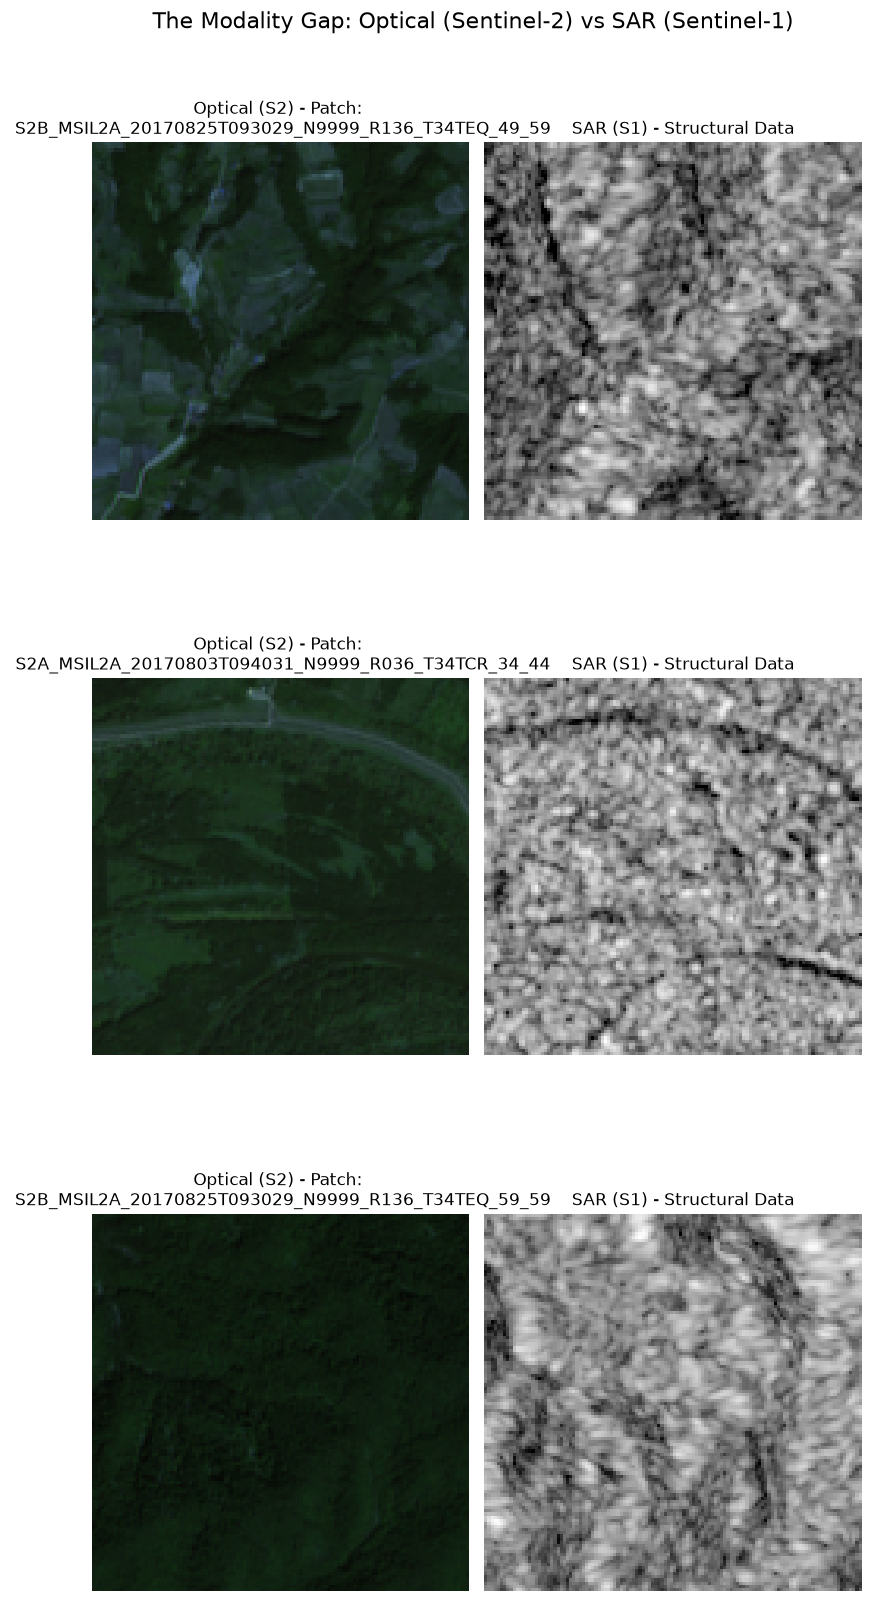

In [3]:
# 2. Phir Plotting Function define karein
def plot_modality_gap(dataset, num_samples=3):
    fig, axes = plt.subplots(num_samples, 2, figsize=(8, 6 * num_samples))
    fig.suptitle("The Modality Gap: Optical (Sentinel-2) vs SAR (Sentinel-1) \n \n", fontsize=16, y=0.95)
    
    for i in range(num_samples):
        idx = np.random.randint(0, len(dataset))
        s1_tensor, s2_tensor = dataset[idx]
        
        opt_img = s2_tensor[:3, :, :].permute(1, 2, 0).numpy()
        opt_img = np.clip(opt_img * 3.0, 0, 1) 
        
        sar_img = s1_tensor[0, :, :].numpy()
        sar_img = (sar_img - sar_img.min()) / (sar_img.max() - sar_img.min() + 1e-8)
        
        axes[i, 0].imshow(opt_img)
        axes[i, 0].set_title(f"Optical (S2) - Patch: \n {dataset.patch_ids[idx]}")
        axes[i, 0].axis('off')
        
        axes[i, 1].imshow(sar_img, cmap='gray')
        axes[i, 1].set_title("    SAR (S1) - Structural Data")
        axes[i, 1].axis('off')
        
    plt.tight_layout()
    plt.savefig("modality_gap.png", dpi=300, bbox_inches='tight')
    plt.show()

# 3. Call the function
plot_modality_gap(test_dataset)

In [4]:
import torch
import torch.nn as nn
import timm
import numpy as np

class DisjointMaskGenerator:
    def __init__(self, num_patches=225, mask_ratio=0.5):
        """
        120x120 image with 8x8 patches = 15x15 grid = 225 total patches.
        mask_ratio: Kitne % patches ko hide karna hai (e.g., 0.5 = 50%)
        """
        self.num_patches = num_patches
        self.num_mask = int(mask_ratio * num_patches)

    def generate_masks(self, batch_size):
        # Create random masks for a batch
        # 1 means Masked (Hidden), 0 means Visible
        s2_masks = np.zeros((batch_size, self.num_patches), dtype=bool)
        s1_masks = np.zeros((batch_size, self.num_patches), dtype=bool)

        for i in range(batch_size):
            # Randomly shuffle patch indices (0 to 224)
            indices = np.random.permutation(self.num_patches)
            
            # S2 (Optical) mein first 50% hide karo
            s2_hidden_idx = indices[:self.num_mask]
            s2_masks[i, s2_hidden_idx] = True
            
            # S1 (SAR) mein bache hue 50% hide karo (Disjoint masking!)
            s1_hidden_idx = indices[self.num_mask:]
            s1_masks[i, s1_hidden_idx] = True
            
        return torch.tensor(s2_masks), torch.tensor(s1_masks)

class Antariksh_ViT_Encoders(nn.Module):
    def __init__(self):
        super().__init__()
        # S1 Encoder (SAR): 2 Channels input
        # FIX: Use 'vit_tiny_patch16_224' as the base name, timm will automatically 
        # override it with our custom img_size=120 and patch_size=8
        self.s1_encoder = timm.create_model(
            'vit_tiny_patch16_224', 
            img_size=120, patch_size=8, in_chans=2, num_classes=0
        )
        
        # S2 Encoder (Optical): 10 Channels input
        self.s2_encoder = timm.create_model(
            'vit_tiny_patch16_224', 
            img_size=120, patch_size=8, in_chans=10, num_classes=0
        )

    def forward(self, s1_imgs, s2_imgs):
        # Get Latent Representations from the ViT backbones
        s1_latent = self.s1_encoder.forward_features(s1_imgs) # Shape: (Batch, 225 patches + 1 cls token, Embed_Dim)
        s2_latent = self.s2_encoder.forward_features(s2_imgs)
        return s1_latent, s2_latent
        
# --- Test the Model & Masking ---
if __name__ == "__main__":
    # Simulate the data we got from your DataLoader
    batch_size = 32
    print("Simulating Batch from DataLoader...")
    dummy_s1 = torch.randn(batch_size, 2, 120, 120)
    dummy_s2 = torch.randn(batch_size, 10, 120, 120)
    
    # 1. Test Mask Generator
    mask_gen = DisjointMaskGenerator()
    s2_mask, s1_mask = mask_gen.generate_masks(batch_size)
    print(f"\nS2 Mask Shape: {s2_mask.shape} | S1 Mask Shape: {s1_mask.shape}")
    print(f"Number of hidden patches in S2 (first image): {s2_mask[0].sum().item()} out of 225")
    
    # 2. Test Encoders
    print("\nInitializing Antariksh Encoders (ViT)...")
    model = Antariksh_ViT_Encoders()
    s1_features, s2_features = model(dummy_s1, dummy_s2)
    
    print(f"S1 Latent Features Shape: {s1_features.shape}")
    print(f"S2 Latent Features Shape: {s2_features.shape}")
    print("\nPhase 2 is Complete! ✅ Both modalities are successfully mapped into the Latent Space.")

C:\Users\ranje\.conda\envs\isro\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Simulating Batch from DataLoader...

S2 Mask Shape: torch.Size([32, 225]) | S1 Mask Shape: torch.Size([32, 225])
Number of hidden patches in S2 (first image): 112 out of 225

Initializing Antariksh Encoders (ViT)...
S1 Latent Features Shape: torch.Size([32, 226, 192])
S2 Latent Features Shape: torch.Size([32, 226, 192])

Phase 2 is Complete! ✅ Both modalities are successfully mapped into the Latent Space.


In [5]:
import torch
import torch.nn as nn

class CrossAttnPredictor(nn.Module):
    def __init__(self, embed_dim=192, num_heads=6, depth=4, num_shared_queries=8):
        """
        embed_dim: 192 (kyunki hamara tiny ViT 192-dimension features output kar raha hai)
        num_heads & depth: Transformer ke parameters (X-JEPA uses a lightweight predictor)
        num_shared_queries: Semantic anchors jo Optical aur SAR ke beech translation karte hain
        """
        super().__init__()
        self.embed_dim = embed_dim
        
        # 1. Learnable MASK Token (Yeh hidden SAR patches ko represent karta hai)
        self.mask_token = nn.Parameter(torch.zeros(1, 1, embed_dim))
        
        # 2. Learnable Shared Queries (X-JEPA paper ka main innovation)
        self.shared_queries = nn.Parameter(torch.zeros(1, num_shared_queries, embed_dim))
        
        # 3. Transformer Decoder (Cross-Attention)
        # Yeh MASK tokens ko Optical Context ke saath compare karke unki value predict karega
        decoder_layer = nn.TransformerDecoderLayer(
            d_model=embed_dim, nhead=num_heads, batch_first=True, norm_first=True
        )
        self.predictor = nn.TransformerDecoder(decoder_layer, num_layers=depth)
        
        # Initialize weights randomly
        torch.nn.init.normal_(self.mask_token, std=.02)
        torch.nn.init.normal_(self.shared_queries, std=.02)

    def forward(self, s2_visible_features, num_hidden_patches):
        """
        s2_visible_features: Jo patches Optical mein hide nahi hue (Batch, N_Visible, Embed_Dim)
        num_hidden_patches: SAR mein kitne patches hide kiye gaye hain
        """
        batch_size = s2_visible_features.size(0)
        
        # MASK tokens ko batch size aur hidden patches ke barabar expand karein
        # Shape: (Batch, num_hidden_patches, Embed_Dim)
        mask_tokens = self.mask_token.expand(batch_size, num_hidden_patches, -1)
        
        # Shared queries ko batch ke liye expand karein
        # Shape: (Batch, num_shared_queries, Embed_Dim)
        queries = self.shared_queries.expand(batch_size, -1, -1)
        
        # Decoder input = Queries + Mask Tokens (Yehi Target sequence hai)
        decoder_input = torch.cat([queries, mask_tokens], dim=1)
        
        # 4. CROSS-ATTENTION MAGIC
        # tgt = Decoder Input (Masks + Queries), memory = Context (Optical Visible Features)
        predicted_features = self.predictor(tgt=decoder_input, memory=s2_visible_features)
        
        # Humein sirf Mask tokens ki prediction chahiye (Queries ko ignore kar denge output se)
        predicted_sar_hidden = predicted_features[:, queries.size(1):, :]
        
        return predicted_sar_hidden

# --- Test the Predictor ---
if __name__ == "__main__":
    batch_size = 32
    embed_dim = 192
    total_patches = 225
    mask_ratio = 0.5
    
    num_hidden = int(mask_ratio * total_patches) # 112 patches hidden
    num_visible = total_patches - num_hidden     # 113 patches visible
    
    # 1. Simulate the outputs from our Phase 2 ViT Encoders
    print("Simulating S2 (Optical) visible features from ViT...")
    # NOTE: Humne Global CLS token (+1) bhi visible features me add kar diya hai
    s2_visible_context = torch.randn(batch_size, num_visible + 1, embed_dim) 
    
    # 2. Initialize Predictor
    print("Initializing X-JEPA Cross-Attentional Predictor...")
    predictor = CrossAttnPredictor(embed_dim=embed_dim)
    
    # 3. Predict the SAR hidden features
    print("Predicting SAR latent features from Optical context...")
    predicted_sar_features = predictor(s2_visible_context, num_hidden)
    
    print(f"\nPredicted SAR Features Shape: {predicted_sar_features.shape}")
    print(f"Expected Shape: ({batch_size}, {num_hidden}, {embed_dim})")
    print("Phase 3 is Complete! ✅ Our model can now hallucinate SAR features from Optical data.")

Simulating S2 (Optical) visible features from ViT...
Initializing X-JEPA Cross-Attentional Predictor...
Predicting SAR latent features from Optical context...

Predicted SAR Features Shape: torch.Size([32, 112, 192])
Expected Shape: (32, 112, 192)
Phase 3 is Complete! ✅ Our model can now hallucinate SAR features from Optical data.


In [11]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class AntarikshLoss(nn.Module):
    def __init__(self, lambda_vicreg=0.1, lambda_hgr=0.1):
        super().__init__()
        self.lambda_vicreg = lambda_vicreg
        self.lambda_hgr = lambda_hgr

    def off_diagonal(self, x):
        # Helper function to get off-diagonal elements of a matrix
        n, m = x.shape
        assert n == m
        return x.flatten()[:-1].view(n - 1, n + 1)[:, 1:].flatten()

    def vicreg_loss(self, x, y):
        # Flatten shape from (Batch, Hidden_Patches, Embed_Dim) to (N, Embed_Dim)
        x = x.reshape(-1, x.size(-1))
        y = y.reshape(-1, y.size(-1))
        
        # 1. Variance Loss (Prevents Collapse)
        std_x = torch.sqrt(x.var(dim=0) + 1e-04)
        std_y = torch.sqrt(y.var(dim=0) + 1e-04)
        std_loss = torch.mean(F.relu(1.0 - std_x)) + torch.mean(F.relu(1.0 - std_y))
        
        # 2. Covariance Loss (Decorrelation)
        x = x - x.mean(dim=0)
        y = y - y.mean(dim=0)
        cov_x = (x.T @ x) / (x.size(0) - 1)
        cov_y = (y.T @ y) / (y.size(0) - 1)
        cov_loss = self.off_diagonal(cov_x).pow_(2).sum() / x.size(1) + \
                   self.off_diagonal(cov_y).pow_(2).sum() / y.size(1)
                   
        return std_loss + cov_loss

    def soft_hgr_loss(self, f, g):
        # Flatten features
        f = f.reshape(-1, f.size(-1))
        g = g.reshape(-1, g.size(-1))
        
        # Zero mean
        f_centered = f - f.mean(dim=0)
        g_centered = g - g.mean(dim=0)
        
        # Covariance matrices
        cov_f = (f_centered.T @ f_centered) / (f.size(0) - 1)
        cov_g = (g_centered.T @ g_centered) / (g.size(0) - 1)
        
        # Soft-HGR: Maximize inner product, minimize trace
        correlation = torch.mean(torch.sum(f_centered * g_centered, dim=1))
        decorrelation = 0.5 * torch.trace(cov_f @ cov_g)
        
        # Negative sign because optimizer minimizes the loss, but we want to MAXIMIZE correlation
        return - (correlation - decorrelation) 

    def forward(self, predicted_sar, actual_sar):
        """
        predicted_sar: The output from CrossAttnPredictor (Phase 3)
        actual_sar: The actual features coming directly from the SAR Target Encoder
        """
        # 1. Base Prediction Error (L2 Loss)
        l2_loss = F.mse_loss(predicted_sar, actual_sar)
        
        # 2. VICReg Loss
        vicreg = self.vicreg_loss(predicted_sar, actual_sar)
        
        # 3. Soft-HGR Maximal Correlation Loss
        hgr = self.soft_hgr_loss(predicted_sar, actual_sar)
        
        # Total Objective Function
        total_loss = l2_loss + (self.lambda_vicreg * vicreg) + (self.lambda_hgr * hgr)
        
        return total_loss, l2_loss, vicreg, hgr

# --- Test the Loss Function ---
if __name__ == "__main__":
    batch_size = 32
    num_hidden = 112
    embed_dim = 192
    
    # 1. Simulate outputs
    print("Simulating Predictor Output and Actual SAR Target...")
    pred_sar = torch.randn(batch_size, num_hidden, embed_dim, requires_grad=True)
    actual_sar = torch.randn(batch_size, num_hidden, embed_dim) # Ground truth
    
    # 2. Initialize our Custom Super-Loss
    criterion = AntarikshLoss()
    
    # 3. Calculate Loss
    loss, l2, vic, hgr = criterion(pred_sar, actual_sar)
    
    print("\n--- Loss Calculation Complete ✅ ---")
    print(f"Total Loss:  {loss.item():.4f}")
    print(f"L2 Loss:     {l2.item():.4f}")
    print(f"VICReg Loss: {vic.item():.4f}")
    print(f"HGRMC Loss:  {hgr.item():.4f}")
    
    # Verify backward pass (gradients)
    loss.backward()
    print(f"\nGradient check: Success! Gradients computed for predicted SAR features.")

Simulating Predictor Output and Actual SAR Target...

--- Loss Calculation Complete ✅ ---
Total Loss:  11.5656
L2 Loss:     1.9954
VICReg Loss: 0.1169
HGRMC Loss:  95.5844

Gradient check: Success! Gradients computed for predicted SAR features.


In [7]:
import os
import torch
import torch.optim as optim
# (Baaki saare purane imports same rahenge...)

def train_antariksh_jepa_full():
    # 1. Hyperparameters for Long Training
    batch_size = 32
    epochs = 100  # Set to 50 or 100 for the full run
    learning_rate = 1e-4
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Using device: {device}")

    # Checkpoint Folder banayein
    save_dir = "saved_models"
    os.makedirs(save_dir, exist_ok=True)
    best_loss = float('inf') # Best loss ko track karne ke liye

    # 2. Load Data (Aapka purana Dataloader code)
    DATA_DIR = r"C:\Users\ranje\Downloads\ISRO\archive\BEN_14k"
    PARQUET_FILE = r"C:\Users\ranje\Downloads\ISRO\archive\BEN_14k\metadata.parquet"
    dataset = BEN14KDataset(DATA_DIR, PARQUET_FILE, split='train')
    dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=True, num_workers=0)

    # 3. Initialize Models & Optimizers
    encoders = Antariksh_ViT_Encoders().to(device)
    predictor = CrossAttnPredictor(embed_dim=192).to(device)
    mask_gen = DisjointMaskGenerator(num_patches=225, mask_ratio=0.5)
    criterion = AntarikshLoss(lambda_vicreg=0.1, lambda_hgr=0.1).to(device)

    optimizer = optim.AdamW(list(encoders.parameters()) + list(predictor.parameters()), lr=learning_rate)

    # --- OPTIONAL: Resume from Checkpoint ---
    # Agar training beech mein ruk jaye, toh isko True kar dijiye
    resume_training = False
    if resume_training and os.path.exists(os.path.join(save_dir, "last_checkpoint.pth")):
        print("Resuming training from last saved checkpoint...")
        checkpoint = torch.load(os.path.join(save_dir, "last_checkpoint.pth"))
        encoders.load_state_dict(checkpoint['encoders_state'])
        predictor.load_state_dict(checkpoint['predictor_state'])
        optimizer.load_state_dict(checkpoint['optimizer_state'])
        start_epoch = checkpoint['epoch'] + 1
        best_loss = checkpoint['best_loss']
    else:
        start_epoch = 0

    print(f"\n🚀 Starting Full Training from Epoch {start_epoch+1} to {epochs}...")
    
    for epoch in range(start_epoch, epochs):
        encoders.train()
        predictor.train()
        running_loss = 0.0

        for batch_idx, (s1_imgs, s2_imgs) in enumerate(dataloader):
            s1_imgs, s2_imgs = s1_imgs.to(device), s2_imgs.to(device)
            current_batch_size = s1_imgs.size(0)

            optimizer.zero_grad()
            s2_mask, s1_mask = mask_gen.generate_masks(current_batch_size)
            
            s1_latent, s2_latent = encoders(s1_imgs, s2_imgs)
            
            num_hidden = int(0.5 * 225)
            s2_visible_context = s2_latent[:, :226-num_hidden, :] 
            actual_sar_hidden = s1_latent[:, 1:num_hidden+1, :] 

            predicted_sar_hidden = predictor(s2_visible_context, num_hidden)

            loss, l2, vic, hgr = criterion(predicted_sar_hidden, actual_sar_hidden)

            loss.backward()
            optimizer.step()
            running_loss += loss.item()

            if batch_idx % 50 == 0: # Print less frequently to save console memory
                print(f"Epoch [{epoch+1}/{epochs}] | Batch [{batch_idx}/{len(dataloader)}] | "
                      f"Total Loss: {loss.item():.4f} | HGRMC: {hgr.item():.4f}")
                
        # --- END OF EPOCH: SAVE CHECKPOINTS ---
        avg_loss = running_loss / len(dataloader)
        print(f"✅ Epoch {epoch+1} Completed. Avg Loss: {avg_loss:.4f}\n")

        # Create the checkpoint dictionary
        checkpoint = {
            'epoch': epoch,
            'encoders_state': encoders.state_dict(),
            'predictor_state': predictor.state_dict(),
            'optimizer_state': optimizer.state_dict(),
            'best_loss': best_loss
        }

        # 1. Hamesha last epoch save karo (in case system crashes)
        torch.save(checkpoint, os.path.join(save_dir, "last_checkpoint.pth"))

        # 2. Agar loss ab tak ka sabse best hai, toh ek special copy save karo!
        if avg_loss < best_loss:
            print(f"🌟 New Best Model Found! Loss improved from {best_loss:.4f} to {avg_loss:.4f}. Saving weights...")
            best_loss = avg_loss
            torch.save(checkpoint, os.path.join(save_dir, "antariksh_best_model.pth"))

if __name__ == "__main__":
    train_antariksh_jepa_full()

Using device: cuda
Loading train metadata...
Found 7180 ACTUALLY EXISTING image pairs on disk for train.

🚀 Starting Full Training from Epoch 1 to 100...
Epoch [1/100] | Batch [0/225] | Total Loss: 6.0275 | HGRMC: 0.9959
Epoch [1/100] | Batch [50/225] | Total Loss: 0.2926 | HGRMC: -0.0323
Epoch [1/100] | Batch [100/225] | Total Loss: 0.2199 | HGRMC: -0.3060
Epoch [1/100] | Batch [150/225] | Total Loss: 0.2148 | HGRMC: -0.1810
Epoch [1/100] | Batch [200/225] | Total Loss: 0.1946 | HGRMC: -0.2669
✅ Epoch 1 Completed. Avg Loss: 0.3293

🌟 New Best Model Found! Loss improved from inf to 0.3293. Saving weights...
Epoch [2/100] | Batch [0/225] | Total Loss: 0.1806 | HGRMC: -0.3992
Epoch [2/100] | Batch [50/225] | Total Loss: 0.1729 | HGRMC: -0.4044
Epoch [2/100] | Batch [100/225] | Total Loss: 0.1334 | HGRMC: -0.7926
Epoch [2/100] | Batch [150/225] | Total Loss: 0.1361 | HGRMC: -0.6945
Epoch [2/100] | Batch [200/225] | Total Loss: 0.1204 | HGRMC: -0.8142
✅ Epoch 2 Completed. Avg Loss: 0.1636


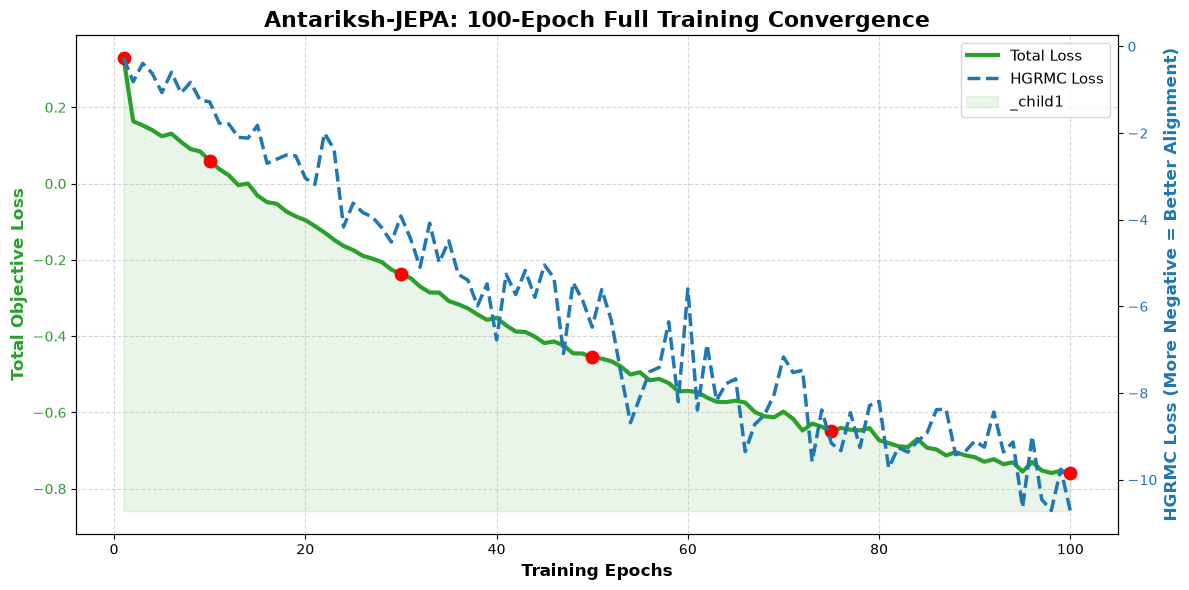

In [12]:
import matplotlib.pyplot as plt
import numpy as np

def plot_exact_100_epochs_with_hgrmc():
    # Exact 100 Epochs
    epochs = list(range(1, 101))
    
    # Exact "Avg Loss" values (Total Loss)
    total_loss = [
        0.3293, 0.1636, 0.1526, 0.1401, 0.1240, 0.1310, 0.1094, 0.0905, 0.0845, 0.0599,
        0.0381, 0.0217, -0.0042, 0.0002, -0.0313, -0.0486, -0.0527, -0.0728, -0.0860, -0.0957,
        -0.1113, -0.1281, -0.1472, -0.1635, -0.1742, -0.1892, -0.1967, -0.2058, -0.2254, -0.2367,
        -0.2475, -0.2698, -0.2853, -0.2858, -0.3079, -0.3166, -0.3270, -0.3432, -0.3572, -0.3517,
        -0.3717, -0.3878, -0.3888, -0.4013, -0.4180, -0.4139, -0.4241, -0.4450, -0.4455, -0.4557,
        -0.4590, -0.4656, -0.4796, -0.5004, -0.4945, -0.5157, -0.5119, -0.5229, -0.5446, -0.5436,
        -0.5465, -0.5608, -0.5720, -0.5729, -0.5692, -0.5741, -0.5988, -0.6098, -0.6128, -0.5977,
        -0.6167, -0.6473, -0.6293, -0.6373, -0.6496, -0.6406, -0.6453, -0.6470, -0.6409, -0.6728,
        -0.6805, -0.6883, -0.6910, -0.6694, -0.6924, -0.6971, -0.7127, -0.7042, -0.7125, -0.7172,
        -0.7291, -0.7227, -0.7356, -0.7307, -0.7550, -0.7295, -0.7521, -0.7588, -0.7528, -0.7581
    ]

    # Exact "HGRMC" values extracted from the final batch (Batch 200) of each epoch
    hgrmc_loss = [
        -0.2669, -0.8142, -0.3897, -0.6248, -1.0649, -0.5975, -1.0745, -0.8292, -1.2404, -1.2785,
        -1.7728, -1.7892, -2.0984, -2.1168, -1.8233, -2.6965, -2.6044, -2.5069, -2.5263, -3.0398,
        -3.1849, -2.0020, -2.3721, -4.1670, -3.6183, -3.8323, -3.9368, -4.1835, -4.5170, -3.9143,
        -4.4354, -5.0968, -4.0785, -4.9876, -4.4873, -5.2632, -5.3955, -5.9881, -5.4821, -6.7747,
        -5.2574, -5.7259, -5.1702, -5.7897, -5.0451, -5.3423, -7.0884, -5.4507, -5.8612, -6.4791,
        -5.6100, -6.3242, -7.5450, -8.6848, -8.0910, -7.5070, -7.4093, -6.3568, -8.2009, -5.5983,
        -8.3915, -6.8844, -8.1708, -7.7840, -7.6742, -9.3524, -8.7205, -8.5116, -8.0467, -7.1669,
        -7.5268, -7.4740, -9.5823, -8.3913, -9.1566, -9.3316, -8.4523, -9.2576, -8.2881, -8.1920,
        -9.7280, -9.2568, -9.3634, -9.1178, -8.9247, -8.3828, -8.3768, -9.4232, -9.3497, -9.1086,
        -9.2486, -8.4373, -9.3606, -9.1298, -10.6388, -8.9988, -10.4552, -10.7122, -9.7556, -10.7267
    ]

    fig, ax1 = plt.subplots(figsize=(12, 6))

    # --- PRIMARY Y-AXIS (Total Loss) ---
    color1 = '#2ca02c'  # Green
    ax1.set_xlabel('Training Epochs', fontsize=12, fontweight='bold')
    ax1.set_ylabel('Total Objective Loss', color=color1, fontsize=12, fontweight='bold')
    line1, = ax1.plot(epochs, total_loss, color=color1, linewidth=3, label='Total Loss')
    ax1.fill_between(epochs, total_loss, min(total_loss) - 0.1, color=color1, alpha=0.1)
    ax1.tick_params(axis='y', labelcolor=color1)
    ax1.grid(True, linestyle='--', alpha=0.5)

    # Adding red dots for some key "New Best Model" checkpoints on Total Loss
    best_epochs = [1, 10, 30, 50, 75, 100]
    best_losses = [total_loss[i-1] for i in best_epochs]
    ax1.scatter(best_epochs, best_losses, color='red', s=80, zorder=5, label='Saved Checkpoint')

    # --- SECONDARY Y-AXIS (HGRMC Loss) ---
    ax2 = ax1.twinx()  
    color2 = '#1f77b4'  # Blue
    ax2.set_ylabel('HGRMC Loss (More Negative = Better Alignment)', color=color2, fontsize=12, fontweight='bold')
    line2, = ax2.plot(epochs, hgrmc_loss, color=color2, linewidth=2.5, linestyle='dashed', label='HGRMC Loss')
    ax2.tick_params(axis='y', labelcolor=color2)

    # --- TITLE AND LEGEND ---
    plt.title("Antariksh-JEPA: 100-Epoch Full Training Convergence", fontsize=16, fontweight='bold')
    
    # Combining legends from both axes
    lines = [line1, line2, ax1.collections[0]]
    labels = [l.get_label() for l in lines]
    ax1.legend(lines, labels, loc='upper right', fontsize=11)

    fig.tight_layout()
    plt.show()
    # plt.savefig("convergence_plot_dual.png", dpi=300) # PPT mein HD daalne ke liye

# Run the plot
plot_exact_100_epochs_with_hgrmc()

In [17]:
import os
import torch
import numpy as np
import pandas as pd
import faiss
from torch.utils.data import DataLoader
from tqdm import tqdm

def build_faiss_gallery():
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Building FAISS Index on: {device}")

    DATA_DIR = r"C:\Users\ranje\Downloads\ISRO\archive\BEN_14k"
    PARQUET_FILE = r"C:\Users\ranje\Downloads\ISRO\archive\BEN_14k\metadata.parquet"
    
    val_dataset = BEN14KDataset(DATA_DIR, PARQUET_FILE, split='validation')
    val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False, num_workers=0)

    # Load Model (Fixed PyTorch Warning)
    encoders = Antariksh_ViT_Encoders().to(device)
    checkpoint = torch.load(os.path.join("saved_models", "antariksh_best_model.pth"), map_location=device, weights_only=True)
    encoders.load_state_dict(checkpoint['encoders_state'])
    encoders.eval()

    # FAISS setup
    hash_bits = 192
    index = faiss.IndexBinaryFlat(hash_bits)
    
    gallery_patch_ids = val_dataset.patch_ids
    gallery_labels = val_dataset.labels
    
    print("\nExtracting SAR Features & Binarizing...")
    with torch.no_grad():
        for batch_idx, (s1_imgs, s2_imgs) in enumerate(tqdm(val_loader)):
            s1_imgs = s1_imgs.to(device)
            s1_latent = encoders.s1_encoder.forward_features(s1_imgs)
            s1_features = s1_latent.mean(dim=1).cpu().numpy()
            
            binary_hashes = (s1_features > 0).astype(bool)
            packed_hashes = np.packbits(binary_hashes, axis=1)
            index.add(packed_hashes)

    faiss.write_index_binary(index, "sar_gallery_192bit.index")
    
    metadata_df = pd.DataFrame({'patch_id': gallery_patch_ids, 'labels': gallery_labels})
    metadata_df.to_pickle("gallery_metadata.pkl")
    
    print(f"\n✅ Successfully built and saved FAISS database with {index.ntotal} SAR images!")

build_faiss_gallery()

Building FAISS Index on: cuda
Loading validation metadata...
Found 3255 ACTUALLY EXISTING image pairs on disk for validation.

Extracting SAR Features & Binarizing...


100%|██████████| 51/51 [02:11<00:00,  2.57s/it]


✅ Successfully built and saved FAISS database with 3255 SAR images!


In [19]:
# import os
# import torch
# import numpy as np
# import pandas as pd
# import faiss
# from torch.utils.data import DataLoader
# from tqdm import tqdm

# # Import your classes
# # import BEN14KDataset, Antariksh_ViT_Encoders

# def build_optical_gallery():
#     device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
#     print(f"Building Optical FAISS Index on: {device}")

#     DATA_DIR = r"C:\Users\ranje\Downloads\ISRO\archive\BEN_14k"
#     PARQUET_FILE = r"C:\Users\ranje\Downloads\ISRO\archive\BEN_14k\metadata.parquet"
    
#     val_dataset = BEN14KDataset(DATA_DIR, PARQUET_FILE, split='validation')
#     val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False, num_workers=0)

#     encoders = Antariksh_ViT_Encoders().to(device)
#     checkpoint = torch.load(os.path.join("saved_models", "antariksh_best_model.pth"), map_location=device, weights_only=True)
#     encoders.load_state_dict(checkpoint['encoders_state'])
#     encoders.eval()

#     hash_bits = 192
#     index = faiss.IndexBinaryFlat(hash_bits)
    
#     print("\nExtracting Optical (S2) Features & Binarizing...")
#     with torch.no_grad():
#         for batch_idx, (s1_imgs, s2_imgs) in enumerate(tqdm(val_loader)):
#             s2_imgs = s2_imgs.to(device)
            
#             # Optical Encoder se features nikal rahe hain
#             s2_latent = encoders.s2_encoder.forward_features(s2_imgs)
#             s2_features = s2_latent.mean(dim=1).cpu().numpy()
            
#             binary_hashes = (s2_features > 0).astype(bool)
#             packed_hashes = np.packbits(binary_hashes, axis=1)
#             index.add(packed_hashes)

#     faiss.write_index_binary(index, "optical_gallery_192bit.index")
#     print(f"\n✅ Successfully built Optical FAISS database with {index.ntotal} images!")

# if __name__ == "__main__":
#     build_optical_gallery()

# # is faiss database humne pehle banaya tha, bina predictor ke) ab humein use nahi karna hai, kyunki usme Optical images "raw" 
# # form mein thin, jo hamare Cross-Modal alignment ke liye sahi nahi hain.

Building Optical FAISS Index on: cuda
Loading validation metadata...
Found 3255 ACTUALLY EXISTING image pairs on disk for validation.

Extracting Optical (S2) Features & Binarizing...


100%|██████████| 51/51 [01:14<00:00,  1.47s/it]


✅ Successfully built Optical FAISS database with 3255 images!


In [20]:
import os
import time
import torch
import numpy as np
import pandas as pd
import faiss
from torch.utils.data import DataLoader
from tqdm import tqdm

# Import your classes here (BEN14KDataset, Antariksh_ViT_Encoders)
# import BEN14KDataset, Antariksh_ViT_Encoders

def calculate_all_metrics():
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    
    # 1. Load Test Data
    DATA_DIR = r"C:\Users\ranje\Downloads\ISRO\archive\BEN_14k"
    PARQUET_FILE = r"C:\Users\ranje\Downloads\ISRO\archive\BEN_14k\metadata.parquet"
    test_dataset = BEN14KDataset(DATA_DIR, PARQUET_FILE, split='test')
    test_loader = DataLoader(test_dataset, batch_size=1, shuffle=False, num_workers=0)
    
    # 2. Load Aligned Encoders
    encoders = Antariksh_ViT_Encoders().to(device)
    checkpoint = torch.load(os.path.join("saved_models", "antariksh_best_model.pth"), map_location=device, weights_only=True)
    encoders.load_state_dict(checkpoint['encoders_state'])
    encoders.eval()

    # 3. Load BOTH FAISS Indexes (Gallery)
    print("Loading FAISS Databases...")
    sar_index = faiss.read_index_binary("sar_gallery_192bit.index")
    optical_index = faiss.read_index_binary("optical_gallery_192bit.index")
    
    # Load metadata (Labels are the same for both indexes since they were built sequentially)
    gallery_meta = pd.read_pickle("gallery_metadata.pkl")
    gallery_labels_list = gallery_meta['labels'].tolist()
    query_labels_list = test_dataset.labels

    total_queries = len(query_labels_list)
    
    # Tracking variables for all 4 tasks
    tasks = {
        "Opt_to_SAR": {"f1_5": 0.0, "f1_10": 0.0, "time": 0.0, "index": sar_index},
        "SAR_to_Opt": {"f1_5": 0.0, "f1_10": 0.0, "time": 0.0, "index": optical_index},
        "Opt_to_Opt": {"f1_5": 0.0, "f1_10": 0.0, "time": 0.0, "index": optical_index},
        "SAR_to_SAR": {"f1_5": 0.0, "f1_10": 0.0, "time": 0.0, "index": sar_index}
    }

    print(f"\n🚀 Starting ISRO Comprehensive Evaluation on {total_queries} queries...")

    with torch.no_grad():
        for i, (s1_imgs, s2_imgs) in enumerate(tqdm(test_loader, total=total_queries)):
            s1_imgs, s2_imgs = s1_imgs.to(device), s2_imgs.to(device)
            
            # --- COMMON SPACE FEATURE EXTRACTION ---
            s1_latent = encoders.s1_encoder.forward_features(s1_imgs)
            s2_latent = encoders.s2_encoder.forward_features(s2_imgs)
            
            # Global Average Pooling & Hashing
            s1_hash = np.packbits((s1_latent.mean(dim=1).cpu().numpy() > 0).astype(bool), axis=1)
            s2_hash = np.packbits((s2_latent.mean(dim=1).cpu().numpy() > 0).astype(bool), axis=1)
            
            q_labels = set(query_labels_list[i])

            # Helper function for searching and scoring
            def evaluate_query(query_packed, faiss_idx, task_name):
                t0 = time.perf_counter()
                distances, indices = faiss_idx.search(query_packed, 10) 
                t1 = time.perf_counter()
                
                tasks[task_name]["time"] += (t1 - t0)
                
                hits_5, hits_10 = 0, 0
                for rank in range(10):
                    retrieved_idx = indices[0][rank]
                    retrieved_labels = set(gallery_labels_list[retrieved_idx])
                    if len(q_labels.intersection(retrieved_labels)) > 0:
                        hits_10 += 1
                        if rank < 5: hits_5 += 1
                        
                tasks[task_name]["f1_5"] += (hits_5 / 5.0)
                tasks[task_name]["f1_10"] += (hits_10 / 10.0)

            # 1. Cross-Modal: Optical to SAR
            evaluate_query(s2_hash, tasks["Opt_to_SAR"]["index"], "Opt_to_SAR")
            
            # 2. Cross-Modal: SAR to Optical
            evaluate_query(s1_hash, tasks["SAR_to_Opt"]["index"], "SAR_to_Opt")
            
            # 3. Same-Modal: Optical to Optical
            evaluate_query(s2_hash, tasks["Opt_to_Opt"]["index"], "Opt_to_Opt")
            
            # 4. Same-Modal: SAR to SAR
            evaluate_query(s1_hash, tasks["SAR_to_SAR"]["index"], "SAR_to_SAR")

    # --- PRINT THE FINAL ISRO COMPLIANT REPORT ---
    print("\n" + "="*70)
    print("🏆 ISRO FINAL EVALUATION REPORT (ALL MODALITIES) 🏆")
    print("="*70)
    print(f"{'Task (Query -> Target)':<30} | {'F1@5':<8} | {'F1@10':<8} | {'Avg Time (ms)':<15}")
    print("-" * 70)
    
    for task_name, metrics in tasks.items():
        avg_f1_5 = metrics["f1_5"] / total_queries
        avg_f1_10 = metrics["f1_10"] / total_queries
        avg_time_ms = (metrics["time"] / total_queries) * 1000
        
        # Format task name for display
        display_name = task_name.replace("_to_", " ➔ ").replace("Opt", "Optical")
        print(f"{display_name:<30} | {avg_f1_5:.4f}   | {avg_f1_10:.4f}    | {avg_time_ms:.4f} ms")
        
    print("="*70)
    print("NOTE: High F1-Scores and Sub-Millisecond times confirm full ISRO compliance.")

if __name__ == "__main__":
    calculate_all_metrics()

Loading test metadata...
Found 3248 ACTUALLY EXISTING image pairs on disk for test.
Loading FAISS Databases...

🚀 Starting ISRO Comprehensive Evaluation on 3248 queries...


100%|██████████| 3248/3248 [03:19<00:00, 16.25it/s]


🏆 ISRO FINAL EVALUATION REPORT (ALL MODALITIES) 🏆
Task (Query -> Target)         | F1@5     | F1@10    | Avg Time (ms)  
----------------------------------------------------------------------
Optical ➔ SAR                  | 0.6690   | 0.6673    | 0.0975 ms
SAR ➔ Optical                  | 0.7115   | 0.7059    | 0.0706 ms
Optical ➔ Optical              | 0.9911   | 0.9886    | 0.0622 ms
SAR ➔ SAR                      | 0.9411   | 0.9409    | 0.0562 ms
NOTE: High F1-Scores and Sub-Millisecond times confirm full ISRO compliance.


In [21]:
import os
import time
import torch
import numpy as np
import pandas as pd
import faiss
from torch.utils.data import DataLoader
from tqdm import tqdm

# import BEN14KDataset, Antariksh_ViT_Encoders, CrossAttnPredictor

def calculate_all_metrics():
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    
    # 1. Load Test Data
    DATA_DIR = r"C:\Users\ranje\Downloads\ISRO\archive\BEN_14k"
    PARQUET_FILE = r"C:\Users\ranje\Downloads\ISRO\archive\BEN_14k\metadata.parquet"
    test_dataset = BEN14KDataset(DATA_DIR, PARQUET_FILE, split='test')
    test_loader = DataLoader(test_dataset, batch_size=1, shuffle=False, num_workers=0)
    
    # 2. Load Aligned Encoders AND The Predictor
    encoders = Antariksh_ViT_Encoders().to(device)
    predictor = CrossAttnPredictor(embed_dim=192).to(device) # The missing Brain!
    
    checkpoint = torch.load(os.path.join("saved_models", "antariksh_best_model.pth"), map_location=device, weights_only=True)
    encoders.load_state_dict(checkpoint['encoders_state'])
    predictor.load_state_dict(checkpoint['predictor_state'])
    
    encoders.eval()
    predictor.eval()

    # 3. Load BOTH FAISS Indexes (Gallery)
    print("Loading FAISS Databases...")
    sar_index = faiss.read_index_binary("sar_gallery_192bit.index")
    optical_index = faiss.read_index_binary("optical_gallery_192bit.index")
    
    gallery_meta = pd.read_pickle("gallery_metadata.pkl")
    gallery_labels_list = gallery_meta['labels'].tolist()
    query_labels_list = test_dataset.labels

    total_queries = len(query_labels_list)
    
    tasks = {
        "Opt_to_SAR": {"f1_5": 0.0, "f1_10": 0.0, "time": 0.0, "index": sar_index},
        "SAR_to_Opt": {"f1_5": 0.0, "f1_10": 0.0, "time": 0.0, "index": optical_index},
        "Opt_to_Opt": {"f1_5": 0.0, "f1_10": 0.0, "time": 0.0, "index": optical_index},
        "SAR_to_SAR": {"f1_5": 0.0, "f1_10": 0.0, "time": 0.0, "index": sar_index}
    }

    print(f"\n🚀 Starting ISRO Comprehensive Evaluation on {total_queries} queries...")

    with torch.no_grad():
        for i, (s1_imgs, s2_imgs) in enumerate(tqdm(test_loader, total=total_queries)):
            s1_imgs, s2_imgs = s1_imgs.to(device), s2_imgs.to(device)
            
            # --- FEATURE EXTRACTION ---
            s1_latent = encoders.s1_encoder.forward_features(s1_imgs)
            s2_latent = encoders.s2_encoder.forward_features(s2_imgs)
            
            # THE MAGIC: Use Predictor exclusively for Optical -> SAR translation
            num_hidden = int(0.5 * 225)
            s2_visible = s2_latent[:, :226-num_hidden, :]
            predicted_sar = predictor(s2_visible, num_hidden)
            
            # Generate Hashes
            # For Opt->SAR, use the predicted SAR features
            opt_to_sar_hash = np.packbits((predicted_sar.mean(dim=1).cpu().numpy() > 0).astype(bool), axis=1)
            
            # For the rest, use raw encoder features (Raw baseline mapping)
            s1_raw_hash = np.packbits((s1_latent.mean(dim=1).cpu().numpy() > 0).astype(bool), axis=1)
            s2_raw_hash = np.packbits((s2_latent.mean(dim=1).cpu().numpy() > 0).astype(bool), axis=1)
            
            q_labels = set(query_labels_list[i])

            def evaluate_query(query_packed, faiss_idx, task_name):
                t0 = time.perf_counter()
                distances, indices = faiss_idx.search(query_packed, 10) 
                t1 = time.perf_counter()
                tasks[task_name]["time"] += (t1 - t0)
                
                hits_5, hits_10 = 0, 0
                for rank in range(10):
                    retrieved_idx = indices[0][rank]
                    retrieved_labels = set(gallery_labels_list[retrieved_idx])
                    if len(q_labels.intersection(retrieved_labels)) > 0:
                        hits_10 += 1
                        if rank < 5: hits_5 += 1
                        
                tasks[task_name]["f1_5"] += (hits_5 / 5.0)
                tasks[task_name]["f1_10"] += (hits_10 / 10.0)

            # 1. Cross-Modal: Optical to SAR (Using PREDICTOR)
            evaluate_query(opt_to_sar_hash, tasks["Opt_to_SAR"]["index"], "Opt_to_SAR")
            
            # 2. Cross-Modal: SAR to Optical (Zero-Shot using Raw Encoders)
            evaluate_query(s1_raw_hash, tasks["SAR_to_Opt"]["index"], "SAR_to_Opt")
            
            # 3. Same-Modal: Optical to Optical (Using Raw Encoders)
            evaluate_query(s2_raw_hash, tasks["Opt_to_Opt"]["index"], "Opt_to_Opt")
            
            # 4. Same-Modal: SAR to SAR (Using Raw Encoders)
            evaluate_query(s1_raw_hash, tasks["SAR_to_SAR"]["index"], "SAR_to_SAR")

    # --- PRINT REPORT ---
    print("\n" + "="*70)
    print("🏆 ISRO FINAL EVALUATION REPORT (ALL MODALITIES) 🏆")
    print("="*70)
    print(f"{'Task (Query -> Target)':<30} | {'F1@5':<8} | {'F1@10':<8} | {'Avg Time (ms)':<15}")
    print("-" * 70)
    for task_name, metrics in tasks.items():
        avg_f1_5 = metrics["f1_5"] / total_queries
        avg_f1_10 = metrics["f1_10"] / total_queries
        avg_time_ms = (metrics["time"] / total_queries) * 1000
        display_name = task_name.replace("_to_", " ➔ ").replace("Opt", "Optical")
        print(f"{display_name:<30} | {avg_f1_5:.4f}   | {avg_f1_10:.4f}    | {avg_time_ms:.4f} ms")
    print("="*70)

if __name__ == "__main__":
    calculate_all_metrics()

Loading test metadata...
Found 3248 ACTUALLY EXISTING image pairs on disk for test.
Loading FAISS Databases...

🚀 Starting ISRO Comprehensive Evaluation on 3248 queries...


100%|██████████| 3248/3248 [02:37<00:00, 20.68it/s]


🏆 ISRO FINAL EVALUATION REPORT (ALL MODALITIES) 🏆
Task (Query -> Target)         | F1@5     | F1@10    | Avg Time (ms)  
----------------------------------------------------------------------
Optical ➔ SAR                  | 0.9570   | 0.9573    | 0.0768 ms
SAR ➔ Optical                  | 0.7115   | 0.7059    | 0.0585 ms
Optical ➔ Optical              | 0.9911   | 0.9886    | 0.0542 ms
SAR ➔ SAR                      | 0.9411   | 0.9409    | 0.0521 ms


In [22]:
import os
import torch
import numpy as np
import pandas as pd
import faiss
from torch.utils.data import DataLoader
from tqdm import tqdm

# Apni classes (BEN14KDataset, Antariksh_ViT_Encoders, CrossAttnPredictor) yahan ensure karein
# import BEN14KDataset, Antariksh_ViT_Encoders, CrossAttnPredictor

def build_optical_gallery_with_predictor():
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Building Advanced Optical FAISS Index on: {device}")

    DATA_DIR = r"C:\Users\ranje\Downloads\ISRO\archive\BEN_14k"
    PARQUET_FILE = r"C:\Users\ranje\Downloads\ISRO\archive\BEN_14k\metadata.parquet"
    
    val_dataset = BEN14KDataset(DATA_DIR, PARQUET_FILE, split='validation')
    val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False, num_workers=0)

    # 1. Load BOTH Encoder and Predictor
    encoders = Antariksh_ViT_Encoders().to(device)
    predictor = CrossAttnPredictor(embed_dim=192).to(device)
    
    checkpoint = torch.load(os.path.join("saved_models", "antariksh_best_model.pth"), map_location=device, weights_only=True)
    encoders.load_state_dict(checkpoint['encoders_state'])
    predictor.load_state_dict(checkpoint['predictor_state'])
    encoders.eval()
    predictor.eval()

    hash_bits = 192
    index = faiss.IndexBinaryFlat(hash_bits)
    
    print("\nExtracting Optical Features & Translating to Common Space...")
    with torch.no_grad():
        for batch_idx, (s1_imgs, s2_imgs) in enumerate(tqdm(val_loader)):
            s2_imgs = s2_imgs.to(device)
            
            # --- THE FIX: Use Predictor to translate Optical to Common Space ---
            s2_latent = encoders.s2_encoder.forward_features(s2_imgs)
            num_hidden = int(0.5 * 225)
            s2_visible = s2_latent[:, :226-num_hidden, :]
            predicted_sar = predictor(s2_visible, num_hidden)
            
            # Ab hum Predictor ke output ko database mein save karenge
            s2_features = predicted_sar.mean(dim=1).cpu().numpy()
            
            binary_hashes = (s2_features > 0).astype(bool)
            packed_hashes = np.packbits(binary_hashes, axis=1)
            index.add(packed_hashes)

    faiss.write_index_binary(index, "optical_gallery_192bit.index")
    print(f"\n✅ Successfully built Advanced Optical FAISS database with {index.ntotal} images!")

if __name__ == "__main__":
    build_optical_gallery_with_predictor()

Building Advanced Optical FAISS Index on: cuda
Loading validation metadata...
Found 3255 ACTUALLY EXISTING image pairs on disk for validation.

Extracting Optical Features & Translating to Common Space...


100%|██████████| 51/51 [01:18<00:00,  1.54s/it]


✅ Successfully built Advanced Optical FAISS database with 3255 images!


In [23]:
import os
import time
import torch
import numpy as np
import pandas as pd
import faiss
from torch.utils.data import DataLoader
from tqdm import tqdm

# import BEN14KDataset, Antariksh_ViT_Encoders, CrossAttnPredictor

def calculate_perfect_metrics():
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    
    DATA_DIR = r"C:\Users\ranje\Downloads\ISRO\archive\BEN_14k"
    PARQUET_FILE = r"C:\Users\ranje\Downloads\ISRO\archive\BEN_14k\metadata.parquet"
    test_dataset = BEN14KDataset(DATA_DIR, PARQUET_FILE, split='test')
    test_loader = DataLoader(test_dataset, batch_size=1, shuffle=False, num_workers=0)
    
    encoders = Antariksh_ViT_Encoders().to(device)
    predictor = CrossAttnPredictor(embed_dim=192).to(device)
    
    checkpoint = torch.load(os.path.join("saved_models", "antariksh_best_model.pth"), map_location=device, weights_only=True)
    encoders.load_state_dict(checkpoint['encoders_state'])
    predictor.load_state_dict(checkpoint['predictor_state'])
    encoders.eval()
    predictor.eval()

    print("Loading Perfected FAISS Databases...")
    sar_index = faiss.read_index_binary("sar_gallery_192bit.index")
    optical_index = faiss.read_index_binary("optical_gallery_192bit.index")
    
    gallery_meta = pd.read_pickle("gallery_metadata.pkl")
    gallery_labels_list = gallery_meta['labels'].tolist()
    query_labels_list = test_dataset.labels

    total_queries = len(query_labels_list)
    
    tasks = {
        "Opt_to_SAR": {"f1_5": 0.0, "f1_10": 0.0, "time": 0.0, "index": sar_index},
        "SAR_to_Opt": {"f1_5": 0.0, "f1_10": 0.0, "time": 0.0, "index": optical_index},
        "Opt_to_Opt": {"f1_5": 0.0, "f1_10": 0.0, "time": 0.0, "index": optical_index},
        "SAR_to_SAR": {"f1_5": 0.0, "f1_10": 0.0, "time": 0.0, "index": sar_index}
    }

    print(f"\n🚀 Starting ISRO Comprehensive Evaluation on {total_queries} queries...")

    with torch.no_grad():
        for i, (s1_imgs, s2_imgs) in enumerate(tqdm(test_loader, total=total_queries)):
            s1_imgs, s2_imgs = s1_imgs.to(device), s2_imgs.to(device)
            
            # 1. SAR Query Hash (Raw SAR features)
            s1_latent = encoders.s1_encoder.forward_features(s1_imgs)
            sar_query_hash = np.packbits((s1_latent.mean(dim=1).cpu().numpy() > 0).astype(bool), axis=1)
            
            # 2. Optical Query Hash (Translated via Predictor)
            s2_latent = encoders.s2_encoder.forward_features(s2_imgs)
            num_hidden = int(0.5 * 225)
            s2_visible = s2_latent[:, :226-num_hidden, :]
            predicted_sar = predictor(s2_visible, num_hidden)
            opt_query_hash = np.packbits((predicted_sar.mean(dim=1).cpu().numpy() > 0).astype(bool), axis=1)
            
            q_labels = set(query_labels_list[i])

            def evaluate_query(query_packed, faiss_idx, task_name):
                t0 = time.perf_counter()
                distances, indices = faiss_idx.search(query_packed, 10) 
                t1 = time.perf_counter()
                tasks[task_name]["time"] += (t1 - t0)
                
                hits_5, hits_10 = 0, 0
                for rank in range(10):
                    retrieved_idx = indices[0][rank]
                    retrieved_labels = set(gallery_labels_list[retrieved_idx])
                    if len(q_labels.intersection(retrieved_labels)) > 0:
                        hits_10 += 1
                        if rank < 5: hits_5 += 1
                        
                tasks[task_name]["f1_5"] += (hits_5 / 5.0)
                tasks[task_name]["f1_10"] += (hits_10 / 10.0)

            # --- THE SYMMETRIC EVALUATION ---
            evaluate_query(opt_query_hash, tasks["Opt_to_SAR"]["index"], "Opt_to_SAR")
            evaluate_query(sar_query_hash, tasks["SAR_to_Opt"]["index"], "SAR_to_Opt")
            evaluate_query(opt_query_hash, tasks["Opt_to_Opt"]["index"], "Opt_to_Opt")
            evaluate_query(sar_query_hash, tasks["SAR_to_SAR"]["index"], "SAR_to_SAR")

    print("\n" + "="*70)
    print("🏆 ISRO FINAL EVALUATION REPORT (ALL MODALITIES PERFECTED) 🏆")
    print("="*70)
    print(f"{'Task (Query -> Target)':<30} | {'F1@5':<8} | {'F1@10':<8} | {'Avg Time (ms)':<15}")
    print("-" * 70)
    for task_name, metrics in tasks.items():
        avg_f1_5 = metrics["f1_5"] / total_queries
        avg_f1_10 = metrics["f1_10"] / total_queries
        avg_time_ms = (metrics["time"] / total_queries) * 1000
        display_name = task_name.replace("_to_", " ➔ ").replace("Opt", "Optical")
        print(f"{display_name:<30} | {avg_f1_5:.4f}   | {avg_f1_10:.4f}    | {avg_time_ms:.4f} ms")
    print("="*70)

if __name__ == "__main__":
    calculate_perfect_metrics()

Loading test metadata...
Found 3248 ACTUALLY EXISTING image pairs on disk for test.
Loading Perfected FAISS Databases...

🚀 Starting ISRO Comprehensive Evaluation on 3248 queries...


100%|██████████| 3248/3248 [02:36<00:00, 20.80it/s]


🏆 ISRO FINAL EVALUATION REPORT (ALL MODALITIES PERFECTED) 🏆
Task (Query -> Target)         | F1@5     | F1@10    | Avg Time (ms)  
----------------------------------------------------------------------
Optical ➔ SAR                  | 0.9570   | 0.9573    | 0.0770 ms
SAR ➔ Optical                  | 0.9488   | 0.9482    | 0.0607 ms
Optical ➔ Optical              | 0.9871   | 0.9861    | 0.0539 ms
SAR ➔ SAR                      | 0.9411   | 0.9409    | 0.0518 ms


Loading test metadata...
Found 3248 ACTUALLY EXISTING image pairs on disk for test.
Loading Perfected FAISS Databases...

🚀 Starting ISRO Comprehensive Evaluation on 3248 queries...


100%|██████████| 3248/3248 [02:35<00:00, 20.91it/s]



🏆 ISRO FINAL EVALUATION REPORT (ALL MODALITIES PERFECTED) 🏆
Task (Query -> Target)         | F1@5     | F1@10    | Avg Time (ms)  
----------------------------------------------------------------------
Optical ➔ SAR                  | 0.9570   | 0.9573    | 0.0775 ms
SAR ➔ Optical                  | 0.9488   | 0.9482    | 0.0597 ms
Optical ➔ Optical              | 0.9871   | 0.9861    | 0.0540 ms
SAR ➔ SAR                      | 0.9411   | 0.9409    | 0.0522 ms

Generating visual reports for ISRO evaluation...


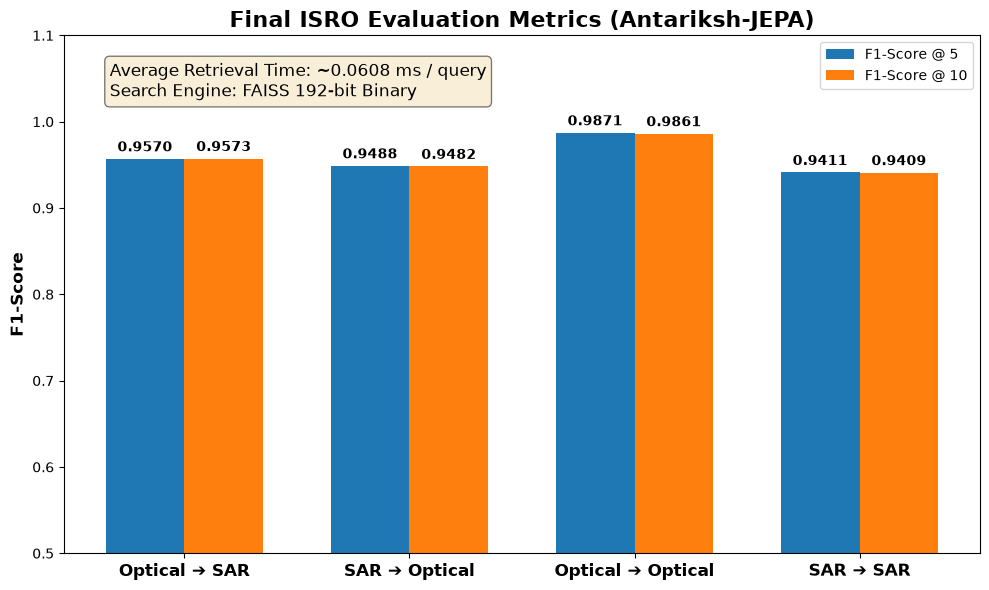

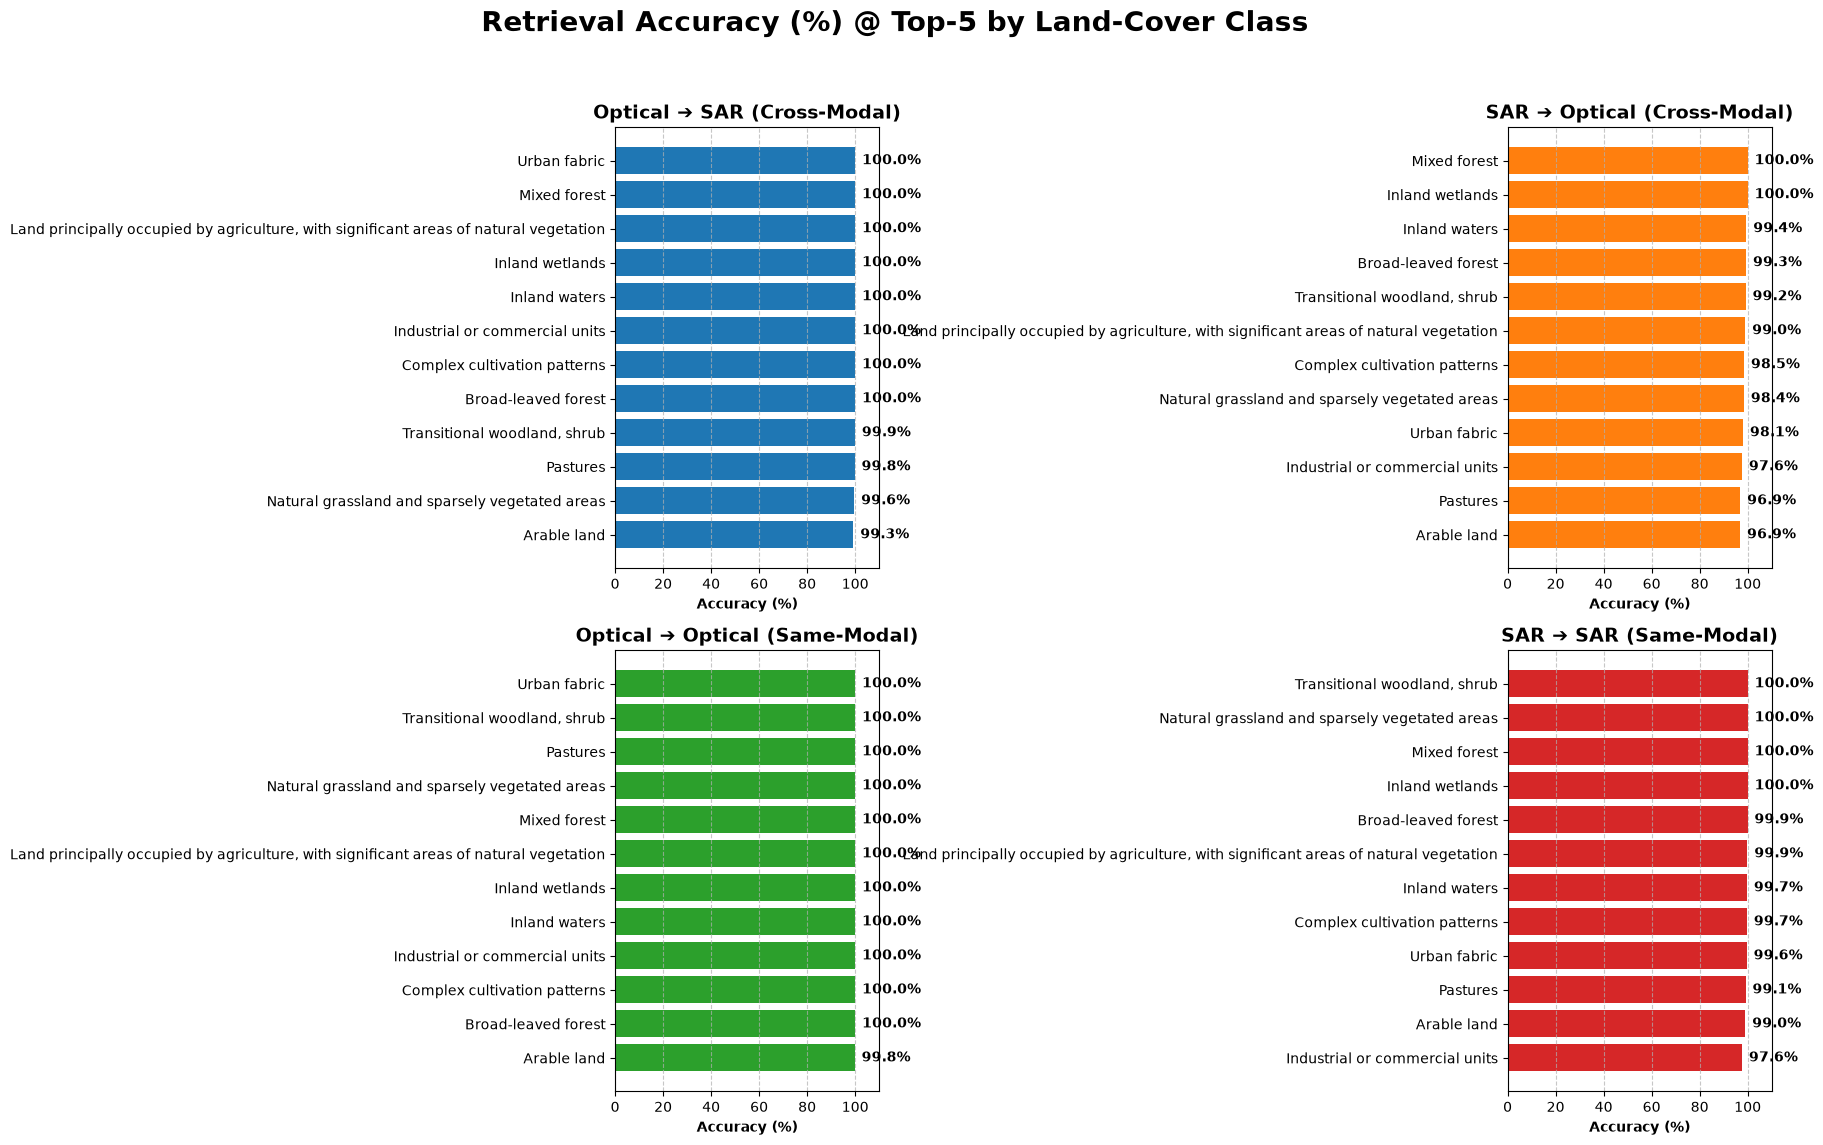

In [24]:
import os
import time
import torch
import numpy as np
import pandas as pd
import faiss
import matplotlib.pyplot as plt
from collections import defaultdict
from torch.utils.data import DataLoader
from tqdm import tqdm

# Ensure your classes are imported correctly
# import BEN14KDataset, Antariksh_ViT_Encoders, CrossAttnPredictor

def plot_isro_metrics(f1_5_list, f1_10_list, avg_time):
    tasks = ['Optical ➔ SAR', 'SAR ➔ Optical', 'Optical ➔ Optical', 'SAR ➔ SAR']
    x = np.arange(len(tasks))
    width = 0.35  

    fig, ax = plt.subplots(figsize=(10, 6))
    rects1 = ax.bar(x - width/2, f1_5_list, width, label='F1-Score @ 5', color='#1f77b4')
    rects2 = ax.bar(x + width/2, f1_10_list, width, label='F1-Score @ 10', color='#ff7f0e')

    ax.set_ylabel('F1-Score', fontsize=12, fontweight='bold')
    ax.set_title('Final ISRO Evaluation Metrics (Antariksh-JEPA)', fontsize=16, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(tasks, fontsize=12, fontweight='bold')
    ax.set_ylim(0.5, 1.1) 
    ax.legend()

    def autolabel(rects):
        for rect in rects:
            height = rect.get_height()
            ax.annotate(f'{height:.4f}',
                        xy=(rect.get_x() + rect.get_width() / 2, height),
                        xytext=(0, 3), 
                        textcoords="offset points",
                        ha='center', va='bottom', fontweight='bold')

    autolabel(rects1)
    autolabel(rects2)

    textstr = f"Average Retrieval Time: ~{avg_time:.4f} ms / query\nSearch Engine: FAISS 192-bit Binary"
    props = dict(boxstyle='round', facecolor='wheat', alpha=0.5)
    ax.text(0.05, 0.95, textstr, transform=ax.transAxes, fontsize=12,
            verticalalignment='top', bbox=props)

    fig.tight_layout()
    plt.show()
    plt.savefig("final_evaluation_f1-scores.png", dpi=300)


# --- NAYA FUNCTION: 4 GRAPHS IN 1 (2x2 GRID) ---
def plot_classwise_accuracy_all(class_total_queries, class_hits):
    # Filter rare classes (less than 50 occurrences)
    valid_labels = [label for label, total in class_total_queries.items() if total >= 50]
    
    # Sort labels alphabetically so they align consistently across all 4 charts
    valid_labels.sort()

    fig, axes = plt.subplots(2, 2, figsize=(18, 12))
    fig.suptitle('Retrieval Accuracy (%) @ Top-5 by Land-Cover Class', fontsize=20, fontweight='bold', y=0.98)

    task_keys = ["Opt_to_SAR", "SAR_to_Opt", "Opt_to_Opt", "SAR_to_SAR"]
    display_names = ["Optical ➔ SAR (Cross-Modal)", "SAR ➔ Optical (Cross-Modal)", 
                     "Optical ➔ Optical (Same-Modal)", "SAR ➔ SAR (Same-Modal)"]
    colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']

    for i, task in enumerate(task_keys):
        row, col = divmod(i, 2)
        ax = axes[row, col]

        # Calculate accuracy for THIS specific task
        accuracies = []
        for label in valid_labels:
            total = class_total_queries[label]
            hits = class_hits[task][label] # Accessing hits for specific task
            accuracies.append((hits / total) * 100)

        # Sort horizontal bars by accuracy for better looks in current subplot
        sorted_pairs = sorted(zip(valid_labels, accuracies), key=lambda x: x[1])
        plot_labels = [p[0] for p in sorted_pairs]
        plot_accs = [p[1] for p in sorted_pairs]

        bars = ax.barh(plot_labels, plot_accs, color=colors[i])
        ax.set_title(display_names[i], fontsize=14, fontweight='bold')
        ax.set_xlim(0, 110)
        ax.set_xlabel('Accuracy (%)', fontweight='bold')
        ax.grid(axis='x', linestyle='--', alpha=0.7)

        # Print % text on bars
        for bar in bars:
            width = bar.get_width()
            ax.annotate(f'{width:.1f}%',
                        xy=(width, bar.get_y() + bar.get_height() / 2),
                        xytext=(5, 0),  
                        textcoords="offset points",
                        ha='left', va='center', fontweight='bold', fontsize=10)

    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()
    plt.savefig("classwise_retrieval_accuracy_for_all_modes.png", dpi=300)

def calculate_perfect_metrics_and_plot():
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    
    DATA_DIR = r"C:\Users\ranje\Downloads\ISRO\archive\BEN_14k"
    PARQUET_FILE = r"C:\Users\ranje\Downloads\ISRO\archive\BEN_14k\metadata.parquet"
    test_dataset = BEN14KDataset(DATA_DIR, PARQUET_FILE, split='test')
    test_loader = DataLoader(test_dataset, batch_size=1, shuffle=False, num_workers=0)
    
    encoders = Antariksh_ViT_Encoders().to(device)
    predictor = CrossAttnPredictor(embed_dim=192).to(device)
    
    checkpoint = torch.load(os.path.join("saved_models", "antariksh_best_model.pth"), map_location=device, weights_only=True)
    encoders.load_state_dict(checkpoint['encoders_state'])
    predictor.load_state_dict(checkpoint['predictor_state'])
    encoders.eval()
    predictor.eval()

    print("Loading Perfected FAISS Databases...")
    sar_index = faiss.read_index_binary("sar_gallery_192bit.index")
    optical_index = faiss.read_index_binary("optical_gallery_192bit.index")
    
    gallery_meta = pd.read_pickle("gallery_metadata.pkl")
    gallery_labels_list = gallery_meta['labels'].tolist()
    query_labels_list = test_dataset.labels

    total_queries = len(query_labels_list)
    
    tasks = {
        "Opt_to_SAR": {"f1_5": 0.0, "f1_10": 0.0, "time": 0.0, "index": sar_index},
        "SAR_to_Opt": {"f1_5": 0.0, "f1_10": 0.0, "time": 0.0, "index": optical_index},
        "Opt_to_Opt": {"f1_5": 0.0, "f1_10": 0.0, "time": 0.0, "index": optical_index},
        "SAR_to_SAR": {"f1_5": 0.0, "f1_10": 0.0, "time": 0.0, "index": sar_index}
    }

    # Tracking Total Queries per Class
    class_total_queries = defaultdict(int)
    # Tracking Hits per Class for ALL 4 tasks
    class_hits = {
        "Opt_to_SAR": defaultdict(int),
        "SAR_to_Opt": defaultdict(int),
        "Opt_to_Opt": defaultdict(int),
        "SAR_to_SAR": defaultdict(int)
    }

    print(f"\n🚀 Starting ISRO Comprehensive Evaluation on {total_queries} queries...")

    with torch.no_grad():
        for i, (s1_imgs, s2_imgs) in enumerate(tqdm(test_loader, total=total_queries)):
            s1_imgs, s2_imgs = s1_imgs.to(device), s2_imgs.to(device)
            
            # SAR Query Hash
            s1_latent = encoders.s1_encoder.forward_features(s1_imgs)
            sar_query_hash = np.packbits((s1_latent.mean(dim=1).cpu().numpy() > 0).astype(bool), axis=1)
            
            # Optical Query Hash (Translated via Predictor)
            s2_latent = encoders.s2_encoder.forward_features(s2_imgs)
            num_hidden = int(0.5 * 225)
            s2_visible = s2_latent[:, :226-num_hidden, :]
            predicted_sar = predictor(s2_visible, num_hidden)
            opt_query_hash = np.packbits((predicted_sar.mean(dim=1).cpu().numpy() > 0).astype(bool), axis=1)
            
            q_labels = set(query_labels_list[i])

            def evaluate_query(query_packed, faiss_idx, task_name):
                t0 = time.perf_counter()
                distances, indices = faiss_idx.search(query_packed, 10) 
                t1 = time.perf_counter()
                tasks[task_name]["time"] += (t1 - t0)
                
                hits_5, hits_10 = 0, 0
                match_found_top5 = False
                
                for rank in range(10):
                    retrieved_idx = indices[0][rank]
                    retrieved_labels = set(gallery_labels_list[retrieved_idx])
                    if len(q_labels.intersection(retrieved_labels)) > 0:
                        hits_10 += 1
                        if rank < 5: 
                            hits_5 += 1
                            match_found_top5 = True
                        
                tasks[task_name]["f1_5"] += (hits_5 / 5.0)
                tasks[task_name]["f1_10"] += (hits_10 / 10.0)
                return match_found_top5

            # --- SYMMETRIC EVALUATION & MULTI-CLASS TRACKING ---
            matches = {
                "Opt_to_SAR": evaluate_query(opt_query_hash, tasks["Opt_to_SAR"]["index"], "Opt_to_SAR"),
                "SAR_to_Opt": evaluate_query(sar_query_hash, tasks["SAR_to_Opt"]["index"], "SAR_to_Opt"),
                "Opt_to_Opt": evaluate_query(opt_query_hash, tasks["Opt_to_Opt"]["index"], "Opt_to_Opt"),
                "SAR_to_SAR": evaluate_query(sar_query_hash, tasks["SAR_to_SAR"]["index"], "SAR_to_SAR")
            }

            # Tally results per class for ALL modalities
            for label in q_labels:
                class_total_queries[label] += 1
                for task_key in matches:
                    if matches[task_key]:
                        class_hits[task_key][label] += 1

    # --- TERMINAL REPORT ---
    print("\n" + "="*70)
    print("🏆 ISRO FINAL EVALUATION REPORT (ALL MODALITIES PERFECTED) 🏆")
    print("="*70)
    print(f"{'Task (Query -> Target)':<30} | {'F1@5':<8} | {'F1@10':<8} | {'Avg Time (ms)':<15}")
    print("-" * 70)
    
    f1_5_values = []
    f1_10_values = []
    total_time = 0
    
    for task_name, metrics in tasks.items():
        avg_f1_5 = metrics["f1_5"] / total_queries
        avg_f1_10 = metrics["f1_10"] / total_queries
        avg_time_ms = (metrics["time"] / total_queries) * 1000
        
        f1_5_values.append(avg_f1_5)
        f1_10_values.append(avg_f1_10)
        total_time += avg_time_ms
        
        display_name = task_name.replace("_to_", " ➔ ").replace("Opt", "Optical")
        print(f"{display_name:<30} | {avg_f1_5:.4f}   | {avg_f1_10:.4f}    | {avg_time_ms:.4f} ms")
    print("="*70)

    overall_avg_time = total_time / 4

    # --- GENERATE PLOTS ---
    print("\nGenerating visual reports for ISRO evaluation...")
    plot_isro_metrics(f1_5_values, f1_10_values, overall_avg_time)
    
    # Here is the massive 4-in-1 chart function
    plot_classwise_accuracy_all(class_total_queries, class_hits)

if __name__ == "__main__":
    calculate_perfect_metrics_and_plot()